<a href="https://colab.research.google.com/github/zaidanfaisal-128/yfinance/blob/main/yfinance2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Import Package
import numpy as np
import scipy.stats as ss
import scipy.optimize as so
import matplotlib.pyplot as plt
import yfinance as yf
import pandas as pd
import datetime as dt
import time

In [ ]:
!pip install pingouin
import pingouin as pg

In [1]:
from google.colab import files
uploaded = files.upload() #idx30

Saving idx30.xlsx to idx30.xlsx


In [4]:
# Tickers
idx30 = pd.read_excel("idx30.xlsx")
idx30["Kode JK"] = idx30["Kode"]+".JK"
tickers = list(idx30["Kode JK"])
tickers.remove('AADI.JK')
tickers.remove('PGEO.JK')
tickers.remove('MBMA.JK')
tickers.remove('GOTO.JK')

In [5]:
# Download Data
t0 = time.time()
close_data = pd.DataFrame()
for i in tickers:
  data = yf.download(i,start="2018-1-1", end="2026-10-1")
  close_data[i] = data["Close"]

t1 = time.time()
print()
print(t1-t0,"s")
print()
close_data

/tmp/ipykernel_761/4281476082.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(i,start="2018-1-1", end="2026-10-1")
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_761/4281476082.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(i,start="2018-1-1", end="2026-10-1")
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_761/4281476082.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(i,start="2018-1-1", end="2026-10-1")
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_761/4281476082.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(i,start="2018-1-1", end="2026-10-1")
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_761/4281476082.py:5: 


6.44044303894043 s



,ADRO.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,BMRI.JK,BRPT.JK,CPIN.JK,...,JPFA.JK,KLBF.JK,MDKA.JK,MEDC.JK,PGAS.JK,PTBA.JK,SMGR.JK,TLKM.JK,UNTR.JK,UNVR.JK
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-01,457.147339,536.513550,469.547028,4935.892090,3519.376465,3435.514648,2072.907715,2419.244141,436.604553,2498.865723,...,871.284180,1401.315796,398.577057,617.160645,1017.530212,751.180176,8111.523438,2757.745605,17472.250000,7842.163574
2018-01-02,462.062927,549.706543,477.059723,4876.423340,3519.376465,3392.136963,2067.213135,2373.883301,434.672668,2740.423340,...,904.794983,1434.483032,417.202179,620.627869,1026.251709,763.394409,8418.778320,2739.112305,16855.291016,7838.657715
2018-01-03,449.773926,532.115967,473.303497,4787.220703,3519.376465,3270.679199,2055.823730,2328.522217,413.421936,2782.071289,...,934.955017,1405.461548,406.027130,617.160645,1020.437378,745.072937,8357.327148,2627.311768,16324.706055,7575.614746
2018-01-04,470.665070,518.923035,480.816132,4891.290039,3571.604736,3262.004395,2021.654541,2366.322998,396.035065,2965.321045,...,934.955017,1446.920776,406.027130,620.627869,1023.344482,757.287292,9012.803711,2621.100342,16781.255859,7491.440918
2018-01-05,489.098450,523.320740,492.085266,4935.892090,3575.621582,3227.301758,2044.433838,2366.322998,405.694458,2998.638916,...,931.603699,1459.358276,398.577057,658.766907,1040.787964,796.983765,8930.868164,2658.367676,17484.587891,7575.614746
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-24,2560.000000,1265.151978,3270.000000,4672.814941,6225.000000,3520.000000,3140.000000,4070.000000,1560.000000,3020.000000,...,2062.162109,735.000000,3060.000000,1490.000000,1440.000000,3050.000000,1570.000000,2410.000000,23708.107422,1620.000000
2026-09-25,2600.000000,1289.861938,3230.000000,4594.444824,6250.000000,3500.000000,3150.000000,4080.000000,1510.000000,3010.000000,...,2014.864746,735.000000,3070.000000,1450.000000,1430.000000,3090.000000,1580.000000,2410.000000,23781.734375,1630.000000
2026-09-28,2590.000000,1314.572021,3100.000000,4574.852539,6225.000000,3460.000000,3140.000000,4020.000000,1475.000000,2990.000000,...,1958.108032,720.000000,2920.000000,1495.000000,1440.000000,3180.000000,1515.000000,2370.000000,23928.990234,1635.000000


In [6]:
# Difference date
close_data["date"] = close_data.index
close_data["last_date"] = close_data.shift(1)["date"]
close_data["diff_date"] = close_data["date"] - close_data["last_date"]
close_data

,ADRO.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,BMRI.JK,BRPT.JK,CPIN.JK,...,MEDC.JK,PGAS.JK,PTBA.JK,SMGR.JK,TLKM.JK,UNTR.JK,UNVR.JK,date,last_date,diff_date
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-01,457.147339,536.513550,469.547028,4935.892090,3519.376465,3435.514648,2072.907715,2419.244141,436.604553,2498.865723,...,617.160645,1017.530212,751.180176,8111.523438,2757.745605,17472.250000,7842.163574,2018-01-01,NaT,NaT
2018-01-02,462.062927,549.706543,477.059723,4876.423340,3519.376465,3392.136963,2067.213135,2373.883301,434.672668,2740.423340,...,620.627869,1026.251709,763.394409,8418.778320,2739.112305,16855.291016,7838.657715,2018-01-02,2018-01-01,1 days
2018-01-03,449.773926,532.115967,473.303497,4787.220703,3519.376465,3270.679199,2055.823730,2328.522217,413.421936,2782.071289,...,617.160645,1020.437378,745.072937,8357.327148,2627.311768,16324.706055,7575.614746,2018-01-03,2018-01-02,1 days
2018-01-04,470.665070,518.923035,480.816132,4891.290039,3571.604736,3262.004395,2021.654541,2366.322998,396.035065,2965.321045,...,620.627869,1023.344482,757.287292,9012.803711,2621.100342,16781.255859,7491.440918,2018-01-04,2018-01-03,1 days
2018-01-05,489.098450,523.320740,492.085266,4935.892090,3575.621582,3227.301758,2044.433838,2366.322998,405.694458,2998.638916,...,658.766907,1040.787964,796.983765,8930.868164,2658.367676,17484.587891,7575.614746,2018-01-05,2018-01-04,1 days
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-24,2560.000000,1265.151978,3270.000000,4672.814941,6225.000000,3520.000000,3140.000000,4070.000000,1560.000000,3020.000000,...,1490.000000,1440.000000,3050.000000,1570.000000,2410.000000,23708.107422,1620.000000,2026-09-24,2026-09-23,1 days
2026-09-25,2600.000000,1289.861938,3230.000000,4594.444824,6250.000000,3500.000000,3150.000000,4080.000000,1510.000000,3010.000000,...,1450.000000,1430.000000,3090.000000,1580.000000,2410.000000,23781.734375,1630.000000,2026-09-25,2026-09-24,1 days
2026-09-28,2590.000000,1314.572021,3100.000000,4574.852539,6225.000000,3460.000000,3140.000000,4020.000000,1475.000000,2990.000000,...,1495.000000,1440.000000,3180.000000,1515.000000,2370.000000,23928.990234,1635.000000,2026-09-28,2026-09-25,3 days


In [7]:
# Completing date
t0 = time.time()

for i in range(1,len(close_data)):
  for j in range(close_data.iloc[i]["diff_date"].days-1):
    new = pd.DataFrame()
    for k in tickers:
      new[k] = pd.Series([close_data.iloc[i-1][k] + (j+1)*(close_data.iloc[i][k]-close_data.iloc[i-1][k])/close_data.iloc[i]["diff_date"].days])
    new["date"] = pd.Series([close_data.iloc[i-1]["date"] + (j+1)*close_data.iloc[2]["diff_date"]])
    new["last_date"] = pd.Series([close_data.iloc[i-1]["date"] + j*close_data.iloc[2]["diff_date"]])
    new["diff_date"] = pd.Series([close_data.iloc[2]["diff_date"]])
    close_data = pd.concat([close_data,new], ignore_index=True)
    #print("="*int(j/close_data.iloc[i]["diff_date"].days*100),int(j/close_data.iloc[i]["diff_date"].days*1000)/10,"%",end="\r")
close_data = close_data.sort_values(["date"],ascending=True)

t1 = time.time()
print()
print(t1-t0,"s")
print()


30.738081455230713 s



In [8]:
# Completed
# close_data.to_csv("close.csv")
close_data

,ADRO.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,BMRI.JK,BRPT.JK,CPIN.JK,...,MEDC.JK,PGAS.JK,PTBA.JK,SMGR.JK,TLKM.JK,UNTR.JK,UNVR.JK,date,last_date,diff_date
0,457.147339,536.513550,469.547028,4935.892090,3519.376465,3435.514648,2072.907715,2419.244141,436.604553,2498.865723,...,617.160645,1017.530212,751.180176,8111.523438,2757.745605,17472.250000,7842.163574,2018-01-01,NaT,NaT
1,462.062927,549.706543,477.059723,4876.423340,3519.376465,3392.136963,2067.213135,2373.883301,434.672668,2740.423340,...,620.627869,1026.251709,763.394409,8418.778320,2739.112305,16855.291016,7838.657715,2018-01-02,2018-01-01,1 days
2,449.773926,532.115967,473.303497,4787.220703,3519.376465,3270.679199,2055.823730,2328.522217,413.421936,2782.071289,...,617.160645,1020.437378,745.072937,8357.327148,2627.311768,16324.706055,7575.614746,2018-01-03,2018-01-02,1 days
3,470.665070,518.923035,480.816132,4891.290039,3571.604736,3262.004395,2021.654541,2366.322998,396.035065,2965.321045,...,620.627869,1023.344482,757.287292,9012.803711,2621.100342,16781.255859,7491.440918,2018-01-04,2018-01-03,1 days
4,489.098450,523.320740,492.085266,4935.892090,3575.621582,3227.301758,2044.433838,2366.322998,405.694458,2998.638916,...,658.766907,1040.787964,796.983765,8930.868164,2658.367676,17484.587891,7575.614746,2018-01-05,2018-01-04,1 days
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3193,2596.666667,1298.098633,3186.666667,4587.914062,6241.666667,3486.666667,3146.666667,4060.000000,1498.333333,3003.333333,...,1465.000000,1433.333333,3120.000000,1558.333333,2396.666667,23830.819661,1631.666667,2026-09-26,2026-09-25,1 days
3194,2593.333333,1306.335327,3143.333333,4581.383301,6233.333333,3473.333333,3143.333333,4040.000000,1486.666667,2996.666667,...,1480.000000,1436.666667,3150.000000,1536.666667,2383.333333,23879.904948,1633.333333,2026-09-27,2026-09-26,1 days
2138,2590.000000,1314.572021,3100.000000,4574.852539,6225.000000,3460.000000,3140.000000,4020.000000,1475.000000,2990.000000,...,1495.000000,1440.000000,3180.000000,1515.000000,2370.000000,23928.990234,1635.000000,2026-09-28,2026-09-25,3 days
2139,2470.000000,1304.687988,3160.000000,4604.241211,6150.000000,3440.000000,3170.000000,4030.000000,1445.000000,2970.000000,...,1460.000000,1435.000000,3110.000000,1545.000000,2370.000000,24714.351562,1635.000000,2026-09-29,2026-09-28,1 days


In [9]:
# Validation
close_data["last_date"] = close_data.shift(1)["date"]
close_data["diff_date"] = close_data["date"] - close_data["last_date"]
close_data.groupby("diff_date").count()

,ADRO.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,BMRI.JK,BRPT.JK,CPIN.JK,...,MDKA.JK,MEDC.JK,PGAS.JK,PTBA.JK,SMGR.JK,TLKM.JK,UNTR.JK,UNVR.JK,date,last_date
diff_date,,,,,,,,,,,,,,,,,,,,,
1 days,3194,3194,3194,3194,3194,3194,3194,3194,3194,3194,...,3194,3194,3194,3194,3194,3194,3194,3194,3194,3194


In [10]:
np.array(close_data.groupby("diff_date").count().transpose().values).std()

np.float64(0.0)

In [11]:
close_data.index = close_data["date"]
close_data = close_data[tickers]
close_data

,ADRO.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,BMRI.JK,BRPT.JK,CPIN.JK,...,JPFA.JK,KLBF.JK,MDKA.JK,MEDC.JK,PGAS.JK,PTBA.JK,SMGR.JK,TLKM.JK,UNTR.JK,UNVR.JK
date,,,,,,,,,,,,,,,,,,,,,
2018-01-01,457.147339,536.513550,469.547028,4935.892090,3519.376465,3435.514648,2072.907715,2419.244141,436.604553,2498.865723,...,871.284180,1401.315796,398.577057,617.160645,1017.530212,751.180176,8111.523438,2757.745605,17472.250000,7842.163574
2018-01-02,462.062927,549.706543,477.059723,4876.423340,3519.376465,3392.136963,2067.213135,2373.883301,434.672668,2740.423340,...,904.794983,1434.483032,417.202179,620.627869,1026.251709,763.394409,8418.778320,2739.112305,16855.291016,7838.657715
2018-01-03,449.773926,532.115967,473.303497,4787.220703,3519.376465,3270.679199,2055.823730,2328.522217,413.421936,2782.071289,...,934.955017,1405.461548,406.027130,617.160645,1020.437378,745.072937,8357.327148,2627.311768,16324.706055,7575.614746
2018-01-04,470.665070,518.923035,480.816132,4891.290039,3571.604736,3262.004395,2021.654541,2366.322998,396.035065,2965.321045,...,934.955017,1446.920776,406.027130,620.627869,1023.344482,757.287292,9012.803711,2621.100342,16781.255859,7491.440918
2018-01-05,489.098450,523.320740,492.085266,4935.892090,3575.621582,3227.301758,2044.433838,2366.322998,405.694458,2998.638916,...,931.603699,1459.358276,398.577057,658.766907,1040.787964,796.983765,8930.868164,2658.367676,17484.587891,7575.614746
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-26,2596.666667,1298.098633,3186.666667,4587.914062,6241.666667,3486.666667,3146.666667,4060.000000,1498.333333,3003.333333,...,1995.945841,730.000000,3020.000000,1465.000000,1433.333333,3120.000000,1558.333333,2396.666667,23830.819661,1631.666667
2026-09-27,2593.333333,1306.335327,3143.333333,4581.383301,6233.333333,3473.333333,3143.333333,4040.000000,1486.666667,2996.666667,...,1977.026937,725.000000,2970.000000,1480.000000,1436.666667,3150.000000,1536.666667,2383.333333,23879.904948,1633.333333
2026-09-28,2590.000000,1314.572021,3100.000000,4574.852539,6225.000000,3460.000000,3140.000000,4020.000000,1475.000000,2990.000000,...,1958.108032,720.000000,2920.000000,1495.000000,1440.000000,3180.000000,1515.000000,2370.000000,23928.990234,1635.000000


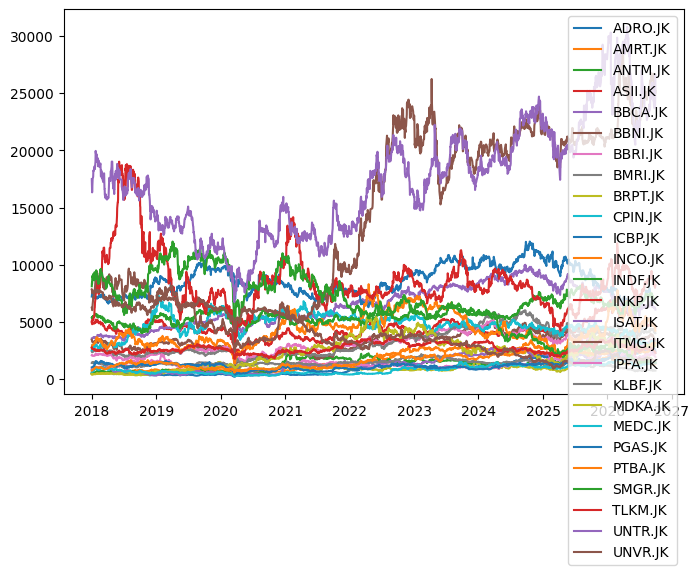

In [12]:
from matplotlib import legend
fig,ax = plt.subplots(1, figsize=(8,5))
ax.plot(close_data)
plt.legend(tickers)
plt.show()

#Stock Return
$r_t=\ln\left(\frac{S_{t+Δt}}{S_t}\right)$

In [13]:
ret = pd.DataFrame()
ret = np.log(close_data/close_data.shift(1)).dropna()
ori = len(ret)
ret

,ADRO.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,BMRI.JK,BRPT.JK,CPIN.JK,...,JPFA.JK,KLBF.JK,MDKA.JK,MEDC.JK,PGAS.JK,PTBA.JK,SMGR.JK,TLKM.JK,UNTR.JK,UNVR.JK
date,,,,,,,,,,,,,,,,,,,,,
2018-01-02,0.010695,0.024293,0.015873,-0.012121,0.000000,-0.012707,-0.002751,-0.018928,-0.004435,0.092275,...,0.037740,0.023393,0.045670,0.005602,0.008535,0.016129,0.037179,-0.006780,-0.035949,-0.000447
2018-01-03,-0.026956,-0.032523,-0.007905,-0.018462,0.000000,-0.036462,-0.005525,-0.019293,-0.050125,0.015083,...,0.032790,-0.020439,-0.027151,-0.005602,-0.005682,-0.024293,-0.007326,-0.041673,-0.031985,-0.034133
2018-01-04,0.045402,-0.025106,0.015748,0.021506,0.014731,-0.002656,-0.016760,0.016103,-0.042966,0.063790,...,0.000000,0.029072,0.000000,0.005602,0.002845,0.016261,0.075508,-0.002367,0.027583,-0.011173
2018-01-05,0.038417,0.008439,0.023167,0.009077,0.001124,-0.010695,0.011205,0.000000,0.024098,0.011173,...,-0.003591,0.008559,-0.018519,0.059638,0.016902,0.051092,-0.009133,0.014118,0.041057,0.011173
2018-01-06,0.028078,0.002797,-0.002548,0.000000,0.001497,0.000000,0.000000,0.004251,-0.001589,-0.029124,...,-0.013277,0.004724,0.009302,0.005249,0.009268,0.007634,0.003053,-0.001559,0.002584,0.002466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-26,-0.001283,0.006365,-0.013507,-0.001422,-0.001334,-0.003817,-0.001059,-0.004914,-0.007756,-0.002217,...,-0.009434,-0.006826,-0.016421,0.010292,0.002328,0.009662,-0.013808,-0.005548,0.002062,0.001022
2026-09-27,-0.001285,0.006325,-0.013692,-0.001424,-0.001336,-0.003831,-0.001060,-0.004938,-0.007817,-0.002222,...,-0.009524,-0.006873,-0.016695,0.010187,0.002323,0.009569,-0.014001,-0.005579,0.002058,0.001021
2026-09-28,-0.001286,0.006285,-0.013882,-0.001427,-0.001338,-0.003846,-0.001061,-0.004963,-0.007878,-0.002227,...,-0.009615,-0.006920,-0.016978,0.010084,0.002317,0.009479,-0.014200,-0.005610,0.002053,0.001020


{'whiskers': [<matplotlib.lines.Line2D at 0x79c8e440afd0>,
 'caps': [<matplotlib.lines.Line2D at 0x79c8e440b250>,
 'boxes': [<matplotlib.lines.Line2D at 0x79c8e440ae90>,
 'medians': [<matplotlib.lines.Line2D at 0x79c8e440b4d0>,
 'fliers': [<matplotlib.lines.Line2D at 0x79c8e440b610>,
 'means': []}

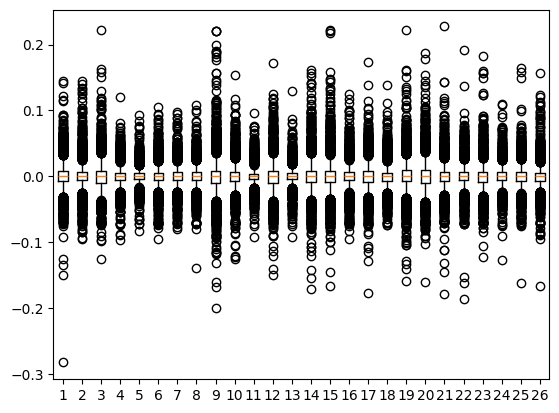

In [14]:
plt.boxplot(ret)

In [ ]:
def out_cleanser(data,x):
  for i in data.keys():
    q = np.quantile(data[i],[i/4 for i in range(5)])
    iqr = q[3] - q[1]
    clean = data[data[i] < q[3] + x*iqr]
    clean = clean[clean[i] > q[1] - x*iqr]
  return clean

In [ ]:
tabel = pd.DataFrame({"X":[],"HZ_stat":[],"p-value":[],"%":[]})
t0 = time.time()

a = 1.5
b = 10
X = np.linspace(a,b,101)
for x in X:
  ret1 = []
  old = len(ret)
  #ret1 = out_cleanser(ret,x)
  for i in ret.keys():
    q    = np.quantile(ret[i],[i/4 for i in range(5)])
    iqr  = q[3] - q[1]
    ret1 = ret[ret[i] < q[3] + x*iqr]
    ret1 = ret1[ret1[i] > q[1] - x*iqr]

  while len(ret1)/ori > 0.5 and len(ret1)/old < 1:
    old = len(ret1)
    #ret1 = out_cleanser(ret1,x)
    for i in ret1.keys():
      q    = np.quantile(ret1[i],[i/4 for i in range(5)])
      iqr  = q[3] - q[1]
      ret1 = ret1[ret1[i] < q[3] + x*iqr]
      ret1 = ret1[ret1[i] > q[1] - x*iqr]

  #print(len(ret1)/ori*100,"%")
  new = pd.DataFrame({"X":[x],"HZ_stat":[pg.multivariate_normality(ret1).hz],"p-value":[pg.multivariate_normality(ret1).pval],"%":[len(ret1)/ori*100]})
  tabel = pd.concat([tabel,new])
  t = time.time()
  print("="*int((x-a)*5),int((x - a)/(b-a)*1000)/10,"%",int((t-t0)*10)/10,"s")

t1 = time.time()
print()
print(t1-t0,"s")
print()

 0.0 % 0.1 s
 0.9 % 0.3 s
 1.9 % 0.5 s
= 2.9 % 0.8 s
= 4.0 % 1.4 s
== 5.0 % 1.7 s
== 5.9 % 2.2 s
== 7.0 % 2.5 s
=== 8.0 % 2.8 s
=== 9.0 % 3.2 s
==== 10.0 % 3.5 s
==== 11.0 % 3.9 s
===== 12.0 % 4.3 s
===== 13.0 % 4.7 s
===== 14.0 % 5.1 s
====== 15.0 % 5.6 s
====== 16.0 % 6.0 s
======= 17.0 % 6.4 s
======= 18.0 % 6.8 s
======== 19.0 % 7.2 s
======== 20.0 % 7.7 s
======== 21.0 % 8.2 s
========= 22.0 % 8.7 s
========= 23.0 % 9.3 s
========== 24.0 % 10.2 s
========== 25.0 % 11.1 s
=========== 26.0 % 12.2 s
=========== 27.0 % 13.4 s
=========== 28.0 % 14.2 s
============ 29.0 % 15.0 s
============ 30.0 % 15.8 s
============= 31.0 % 16.7 s
============= 32.0 % 17.6 s
============== 32.9 % 18.6 s
============== 34.0 % 19.5 s
============== 35.0 % 20.6 s
=============== 36.0 % 21.6 s
=============== 36.9 % 22.6 s
================ 38.0 % 24.1 s
================ 39.0 % 25.7 s
================= 40.0 % 27.5 s
================= 41.0 % 28.6 s
================= 42.0 % 29.7 s
================== 43.0 % 

In [ ]:
tabel

,X,HZ_stat,p-value,%
0,1.500,7.764370,0.0,15.341265
0,1.585,7.354524,0.0,17.407639
0,1.670,6.625397,0.0,21.571697
0,1.755,6.187233,0.0,25.234815
0,1.840,5.915905,0.0,28.271760
...,...,...,...,...
0,9.660,30.956642,0.0,98.653726
0,9.745,31.066350,0.0,98.716343
0,9.830,31.117381,0.0,98.747652
0,9.915,31.188571,0.0,98.810269


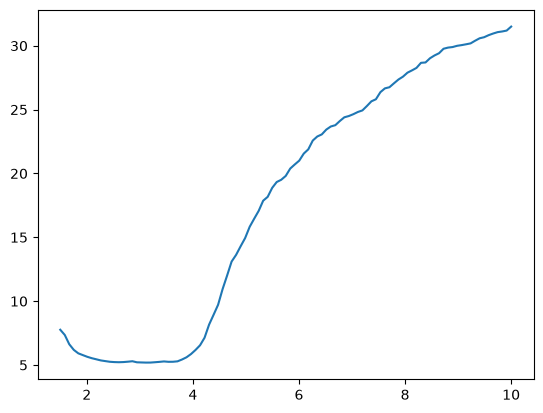

In [ ]:
plt.plot(tabel["X"],tabel["HZ_stat"])
plt.show()

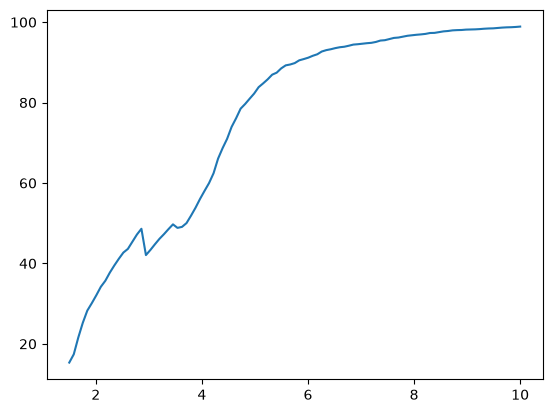

In [ ]:
plt.plot(tabel["X"],tabel["%"])

In [ ]:
x = list(tabel[tabel['HZ_stat'] == tabel['HZ_stat'].min()]["X"])[0]
ret1 = []
old = len(ret)
#ret1 = out_cleanser(ret,x)
for i in ret.keys():
  q    = np.quantile(ret[i],[i/4 for i in range(5)])
  iqr  = q[3] - q[1]
  ret1 = ret[ret[i] < q[3] + x*iqr]
  ret1 = ret1[ret1[i] > q[1] - x*iqr]

while len(ret1)/ori > 0.3 and len(ret1)/old < 1:
  old = len(ret1)
  #ret1 = out_cleanser(ret1,x)
  for i in ret1.keys():
    q    = np.quantile(ret1[i],[i/4 for i in range(5)])
    iqr  = q[3] - q[1]
    ret1 = ret1[ret1[i] < q[3] + x*iqr]
    ret1 = ret1[ret1[i] > q[1] - x*iqr]

In [ ]:
ret1

,ADRO.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,BMRI.JK,BRPT.JK,CPIN.JK,...,JPFA.JK,KLBF.JK,MDKA.JK,MEDC.JK,PGAS.JK,PTBA.JK,SMGR.JK,TLKM.JK,UNTR.JK,UNVR.JK
date,,,,,,,,,,,,,,,,,,,,,
2018-01-13,0.000000,-0.002928,-0.002509,0.000000,0.000743,0.008054,0.000941,0.004107,0.014118,0.001038,...,0.010969,-0.002954,-0.001450,0.013606,-0.002813,0.016019,-0.001577,-0.000807,0.001350,0.002148
2018-01-14,0.000000,-0.002937,-0.002516,0.000000,0.000742,0.007989,0.000940,0.004090,0.013921,0.001037,...,0.010850,-0.002963,-0.001452,0.013423,-0.002821,0.015766,-0.001580,-0.000808,0.001348,0.002144
2018-01-15,0.000000,-0.002946,-0.002522,0.000000,0.000742,0.007926,0.000939,0.004073,0.013730,0.001036,...,0.010734,-0.002972,-0.001455,0.013245,-0.002829,0.015521,-0.001582,-0.000809,0.001346,0.002139
2018-01-20,0.019683,-0.002759,0.006557,-0.004000,0.000371,-0.000885,0.002759,0.000000,-0.006107,-0.011364,...,-0.003396,-0.001957,-0.008511,0.001301,0.016878,0.019048,-0.006107,-0.002407,0.009977,-0.000306
2018-01-21,0.019303,-0.002766,0.006515,-0.004016,0.000371,-0.000885,0.002751,0.000000,-0.006144,-0.011494,...,-0.003407,-0.001961,-0.008584,0.001300,0.016598,0.018692,-0.006144,-0.002413,0.009878,-0.000306
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-20,-0.002535,0.003824,-0.010132,0.000000,-0.003992,-0.002751,-0.001009,-0.004728,0.000000,-0.004260,...,-0.001465,-0.004415,-0.003466,0.003407,0.005602,-0.001080,0.002144,-0.007905,-0.001683,-0.006116
2026-09-21,-0.002541,0.003810,-0.010236,0.000000,-0.004008,-0.002759,-0.001010,-0.004751,0.000000,-0.004278,...,-0.001467,-0.004435,-0.003478,0.003396,0.005571,-0.001082,0.002139,-0.007968,-0.001685,-0.006154
2026-09-26,-0.001283,0.006365,-0.013507,-0.001422,-0.001334,-0.003817,-0.001059,-0.004914,-0.007756,-0.002217,...,-0.009434,-0.006826,-0.016421,0.010292,0.002328,0.009662,-0.013808,-0.005548,0.002062,0.001022


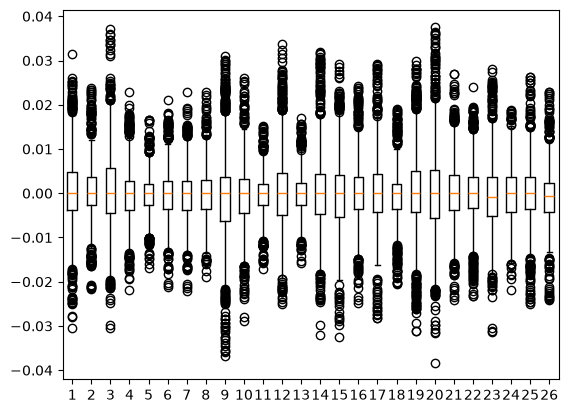

In [ ]:
plt.boxplot(ret1)
plt.show()

In [ ]:
momen = pd.DataFrame()

momen["kode"] = pd.Series(tickers)
momen["ret_skew"] = abs(pd.Series(ss.skew(ret)))
momen["clean_skew"] = abs(pd.Series(ss.skew(ret1)))
momen["ret_kurt"] = pd.Series(ss.kurtosis(ret))
momen["clean_kurt"] = pd.Series(ss.kurtosis(ret1))
momen["ret_nstat"] = pd.Series(ss.normaltest(ret).statistic)
momen["clean_nstat"] = pd.Series(ss.normaltest(ret1).statistic)
momen["ret_npval"] = np.log(pd.Series(ss.normaltest(ret).pvalue))/np.log(10)
momen["clean_npval"] = np.log(pd.Series(ss.normaltest(ret1).pvalue))/np.log(10)
momen

,kode,ret_skew,clean_skew,ret_kurt,clean_kurt,ret_nstat,clean_nstat,ret_npval,clean_npval
0,ADRO.JK,0.483993,0.015894,16.216275,1.230510,837.199557,36.689780,-181.795574,-7.967084
1,AMRT.JK,1.051574,0.246842,9.582109,1.420866,962.872032,57.445115,-209.085005,-12.474048
2,ANTM.JK,1.063580,0.438445,8.910516,1.203091,946.708819,75.667117,-205.575208,-16.430906
3,ASII.JK,0.225364,0.276604,5.977122,0.996240,434.756606,44.390453,-94.406197,-9.639264
4,BBCA.JK,0.400938,0.104903,8.509829,1.407814,595.400861,45.975707,-129.289654,-9.983498
5,BBNI.JK,0.247061,0.162140,6.076585,0.930581,444.776426,31.025368,-96.581974,-6.737073
6,BBRI.JK,0.352476,0.169494,6.013007,0.977400,472.708446,33.339450,-102.647335,-7.239570
7,BMRI.JK,0.083596,0.228718,7.475608,0.856972,479.009770,33.962254,-104.015650,-7.374810
8,BRPT.JK,1.188243,0.055937,11.721887,1.674261,1106.907466,54.401465,-240.361902,-11.813128
9,CPIN.JK,0.307215,0.065972,7.005129,1.658133,503.733680,54.066452,-109.384379,-11.740381


<Axes: xlabel='kode'>

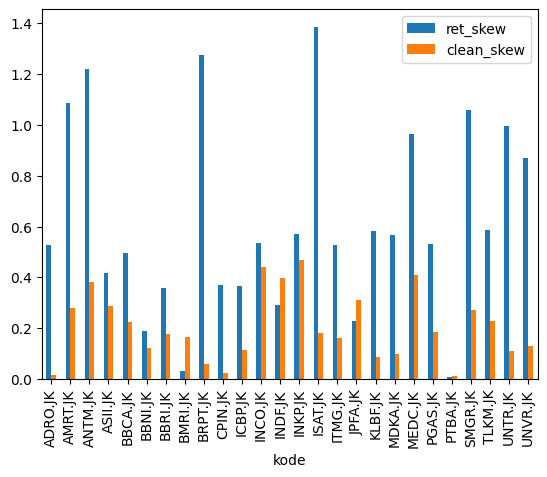

In [ ]:
momen.plot(kind="bar", x="kode", y=["ret_skew","clean_skew"])

<Axes: xlabel='kode'>

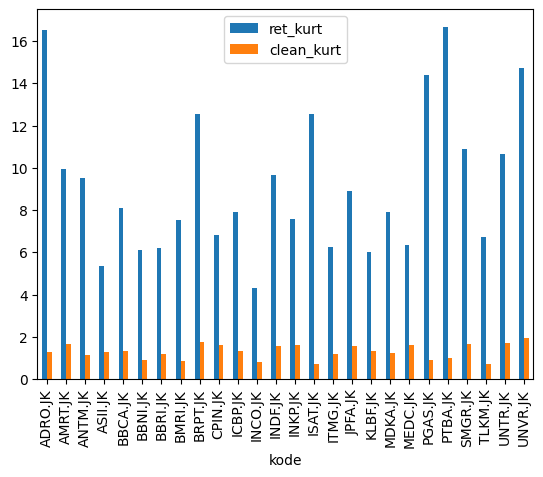

In [ ]:
momen.plot(kind="bar", x="kode", y=["ret_kurt","clean_kurt"])

<Axes: xlabel='kode'>

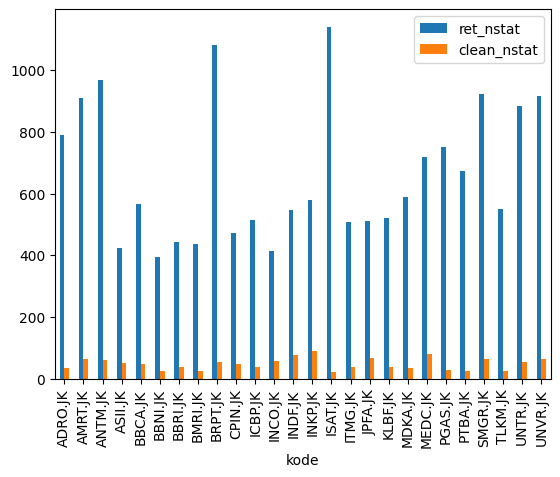

In [ ]:
momen.plot(kind="bar", x="kode", y=["ret_nstat","clean_nstat"])

<Axes: xlabel='kode'>

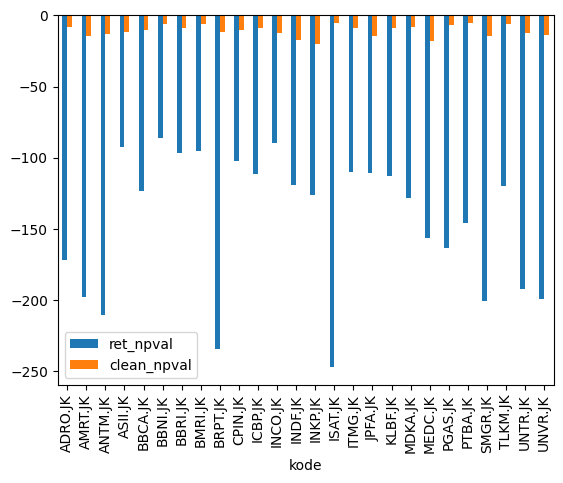

In [ ]:
momen.plot(kind="bar", x="kode", y=["ret_npval","clean_npval"])

In [ ]:
print(ss.normaltest(ret))
print(ss.normaltest(ret1))

NormaltestResult(statistic=array([ 789.95929545,  910.36007886,  968.89991536,  424.65770912,
        566.62351718,  396.31937455,  443.50850985,  437.72976373,
       1080.21183605,  472.19379915,  513.9357317 ,  413.53268894,
        548.56748054,  579.58351852, 1138.56457994,  507.8003537 ,
        510.80244191,  520.12651287,  589.65910348,  719.04539483,
        751.4397212 ,  672.07088836,  923.40846444,  551.55311007,
        884.86447178,  915.60957398]), pvalue=array([2.90080495e-172, 2.07883779e-198, 4.03698022e-211, 6.11998159e-093,
       9.10471984e-124, 8.71648286e-087, 4.93572265e-097, 8.87543245e-096,
       2.72257692e-235, 2.91352883e-103, 2.51347074e-112, 1.59410731e-090,
       7.58726276e-120, 1.39649071e-126, 5.80554266e-248, 5.40199577e-111,
       1.20409033e-111, 1.13752981e-113, 9.06050861e-129, 7.26568212e-157,
       6.71332697e-164, 1.15255290e-146, 3.05070122e-201, 1.70515519e-120,
       7.14695976e-193, 1.50628524e-199]))
NormaltestResult(statistic=array

In [ ]:
print(pg.multivariate_normality(ret, alpha=1e-10))
print(pg.multivariate_normality(ret1, alpha=1e-10))

HZResults(hz=np.float64(31.901736176692374), pval=np.float64(0.0), normal=False)
HZResults(hz=np.float64(5.534185933262199), pval=np.float64(0.0), normal=False)


In [ ]:
def pval(data,power):
  return ss.normaltest((abs(data)**power*np.sign(data))).pvalue

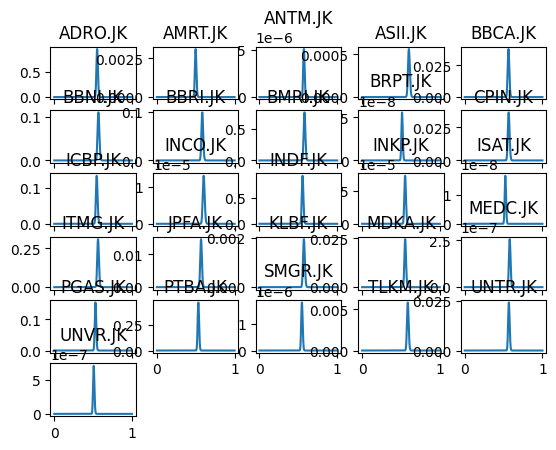

In [ ]:
x_ax = np.linspace(0,1,1000)
for i in range(26):
  plt.subplot(6,5,i+1)
  plt.plot(x_ax,[(pval(ret[tickers[i]],x)) for x in x_ax])
  plt.title(tickers[i])

In [ ]:
power = pd.DataFrame({"idx":[],"kode":[],"power":[]})
for i in range(len(tickers)):
  f = lambda x:-(pval(ret[tickers[i]],x))
  pow = so.minimize(f,.5, method='nelder-mead',options={'xatol': 1e-100}).x[0]
  print(tickers[i], pow, -so.minimize(f,.5, method='nelder-mead',options={'xatol': 1e-100}).fun)
  new0 = pd.DataFrame({"idx":[int(i)],"kode":[tickers[i]],"power":[pow]})
  power = pd.concat([power,new0])
  power.index = power["idx"]
power

ADRO.JK 0.5518583197153932 0.9493612697769411
AMRT.JK 0.49863504581153395 0.003104409924852366
ANTM.JK 0.5710372803321664 5.107878232995726e-06
ASII.JK 0.6016312308376658 0.0005621107535299339
BBCA.JK 0.5626359894871272 0.03798593940896922
BBNI.JK 0.5680883334978719 0.11072736726375801
BBRI.JK 0.5841075704200182 0.09950048684995483
BMRI.JK 0.5788860006141934 0.7676755445919159
BRPT.JK 0.5137725325301286 5.578063855373766e-08
CPIN.JK 0.5652343962265151 0.03618939357407195
ICBP.JK 0.5463408328592774 0.13333506165446385
INCO.JK 0.6020537614851496 1.308145949676494e-05
INDF.JK 0.5543381789695576 0.9344751220238606
INKP.JK 0.5531812876579354 7.249346081141322e-05
ISAT.JK 0.5221787676207899 1.6573051810803666e-08
ITMG.JK 0.563334163464606 0.30958570548891734
JPFA.JK 0.5684127485365026 0.01468172529589557
KLBF.JK 0.5712659677491504 0.0019504682207766607
MDKA.JK 0.5541158827021717 0.024558087235765115
MEDC.JK 0.5786090441048148 2.55726254869862e-07
PGAS.JK 0.5301342755556048 0.1539508733927675

,idx,kode,power
idx,,,
0.0,0.0,ADRO.JK,0.551858
1.0,1.0,AMRT.JK,0.498635
2.0,2.0,ANTM.JK,0.571037
3.0,3.0,ASII.JK,0.601631
4.0,4.0,BBCA.JK,0.562636
5.0,5.0,BBNI.JK,0.568088
6.0,6.0,BBRI.JK,0.584108
7.0,7.0,BMRI.JK,0.578886
8.0,8.0,BRPT.JK,0.513773


In [ ]:
trans = pd.DataFrame()
for i in range(len(tickers)):
  trans[tickers[i]] = (abs(ret[tickers[i]])**(power.loc[i,"power"])*np.sign((ret[tickers[i]])))
trans

,ADRO.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,BMRI.JK,BRPT.JK,CPIN.JK,...,JPFA.JK,KLBF.JK,MDKA.JK,MEDC.JK,PGAS.JK,PTBA.JK,SMGR.JK,TLKM.JK,UNTR.JK,UNVR.JK
date,,,,,,,,,,,,,,,,,,,,,
2018-01-02,0.081733,0.156654,0.093868,-0.070307,0.000000,-0.083738,-0.031944,-0.100610,-0.061804,0.260034,...,0.155252,0.117034,0.180834,0.049795,0.080031,0.110526,0.165764,-0.053206,-0.151356,-0.019916
2018-01-03,-0.136126,-0.181187,-0.063043,-0.090561,0.000000,-0.152406,-0.048003,-0.101729,-0.214843,0.093416,...,0.143327,-0.108348,-0.135561,-0.049795,-0.064502,-0.137525,-0.068293,-0.154611,-0.141640,-0.179952
2018-01-04,0.181507,-0.159247,0.093445,0.099270,0.093193,-0.034415,-0.091789,0.091624,-0.198490,0.211059,...,0.000000,0.132505,0.000000,0.049795,0.044701,0.111004,0.244043,-0.028673,0.130220,-0.102067
2018-01-05,0.165523,0.092465,0.116488,0.059080,0.021910,-0.075929,0.072551,0.000000,0.147470,0.078843,...,-0.040769,0.065897,-0.109663,0.195663,0.114965,0.204498,-0.077026,0.081864,0.163213,0.102067
2018-01-06,0.139224,0.053314,-0.033024,0.000000,0.025744,0.000000,0.000000,0.042380,-0.036472,-0.135500,...,-0.085733,0.046924,0.074880,0.047955,0.083604,0.074145,0.042353,-0.022435,0.033952,0.047388
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-27,0.077238,-0.029450,0.064586,0.027279,0.000000,-0.017169,0.016456,0.024494,0.118905,-0.041811,...,-0.033328,0.051156,0.108011,0.075056,0.034676,0.064217,-0.062685,0.032216,-0.014282,0.000000
2025-12-28,0.076829,-0.029462,0.064284,0.027238,0.000000,-0.017176,0.016448,0.024471,0.117948,-0.041898,...,-0.033376,0.050996,0.106947,0.074566,0.034644,0.064018,-0.062900,0.032161,-0.014287,0.000000
2025-12-29,0.076427,-0.029475,0.063986,0.027197,0.000000,-0.017184,0.016439,0.024447,0.117014,-0.041984,...,-0.033424,0.050838,0.105912,0.074084,0.034611,0.063821,-0.063117,0.032107,-0.014291,0.000000


{'whiskers': [<matplotlib.lines.Line2D at 0x7a84094b3260>,
 'caps': [<matplotlib.lines.Line2D at 0x7a84094b37d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7a84094b2ff0>,
 'medians': [<matplotlib.lines.Line2D at 0x7a84094b3d70>,
 'fliers': [<matplotlib.lines.Line2D at 0x7a84094f00b0>,
 'means': []}

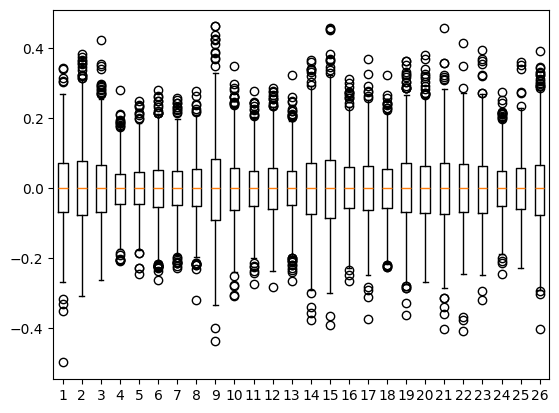

In [ ]:
plt.boxplot(trans)

In [ ]:
print(ss.normaltest(ret))
print(ss.normaltest(trans))

NormaltestResult(statistic=array([ 789.95929545,  910.36007886,  968.89991536,  424.65770912,
        566.62351718,  396.31937455,  443.50850985,  437.72976373,
       1080.21183605,  472.19379915,  513.9357317 ,  413.53268894,
        548.56748054,  579.58351852, 1138.56457994,  507.8003537 ,
        510.80244191,  520.12651287,  589.65910348,  719.04539483,
        751.4397212 ,  672.07088836,  923.40846444,  551.55311007,
        884.86447178,  915.60957398]), pvalue=array([2.90080495e-172, 2.07883779e-198, 4.03698022e-211, 6.11998159e-093,
       9.10471984e-124, 8.71648286e-087, 4.93572265e-097, 8.87543245e-096,
       2.72257692e-235, 2.91352883e-103, 2.51347074e-112, 1.59410731e-090,
       7.58726276e-120, 1.39649071e-126, 5.80554266e-248, 5.40199577e-111,
       1.20409033e-111, 1.13752981e-113, 9.06050861e-129, 7.26568212e-157,
       6.71332697e-164, 1.15255290e-146, 3.05070122e-201, 1.70515519e-120,
       7.14695976e-193, 1.50628524e-199]))
NormaltestResult(statistic=array

In [ ]:
print(pg.multivariate_normality(ret))
print(pg.multivariate_normality(trans))

HZResults(hz=np.float64(31.901736176692374), pval=np.float64(0.0), normal=False)
HZResults(hz=np.float64(3.8218993083072315), pval=np.float64(0.0), normal=False)


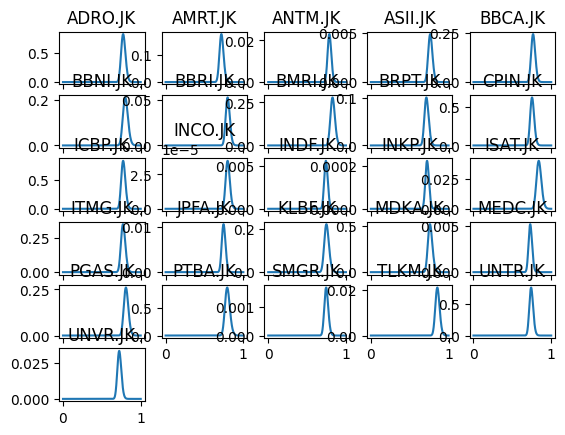

In [ ]:
x_ax = np.linspace(0,1,1000)
for i in range(26):
  plt.subplot(6,5,i+1)
  plt.plot(x_ax,[(pval(ret1[tickers[i]],x)) for x in x_ax])
  plt.title(tickers[i])

In [ ]:
power1 = pd.DataFrame({"idx":[],"kode":[],"power":[]})
for i in range(len(tickers)):
  f = lambda x:-(pval(ret1[tickers[i]],x))
  pow1 = so.minimize(f,.75, method='nelder-mead',options={'xatol': 1e-100}).x[0]
  print(tickers[i], pow1, -so.minimize(f,.75, method='nelder-mead',options={'xatol': 1e-100}).fun)
  new1 = pd.DataFrame({"idx":[int(i)],"kode":[tickers[i]],"power":[pow1]})
  power1 = pd.concat([power1,new1])
  power1.index = power1["idx"]
power1

ADRO.JK 0.7735763704991767 0.8345310921908133
AMRT.JK 0.7173017363995225 0.17812740594869805
ANTM.JK 0.7863935367786327 0.023085290362680082
ASII.JK 0.7631984913256018 0.0048779778826121035
BBCA.JK 0.7666683834045449 0.2455528999923224
BBNI.JK 0.8002868706931625 0.21220604280789004
BBRI.JK 0.7973383085802201 0.05266410975964459
BMRI.JK 0.8270802352577449 0.27891761939530263
BRPT.JK 0.7140051941794807 0.10135713398680027
CPIN.JK 0.7533824694051873 0.6297630205950836
ICBP.JK 0.7737618444312829 0.8344902569977455
INCO.JK 0.797451109438879 3.490266393334015e-05
INDF.JK 0.7415436465293156 0.0055898157633686146
INKP.JK 0.7229007636546156 0.0002227227881956979
ISAT.JK 0.8394113549404213 0.04009929903971289
ITMG.JK 0.7717993226839098 0.3483194408047313
JPFA.JK 0.7448400802910329 0.010525779418033876
KLBF.JK 0.7482554848311337 0.22080860588752427
MDKA.JK 0.7601412484419764 0.519494617215382
MEDC.JK 0.7298827482858536 0.005161842482257897
PGAS.JK 0.809306121242812 0.2602533367430981
PTBA.JK 0.79

,idx,kode,power
idx,,,
0.0,0.0,ADRO.JK,0.773576
1.0,1.0,AMRT.JK,0.717302
2.0,2.0,ANTM.JK,0.786394
3.0,3.0,ASII.JK,0.763198
4.0,4.0,BBCA.JK,0.766668
5.0,5.0,BBNI.JK,0.800287
6.0,6.0,BBRI.JK,0.797338
7.0,7.0,BMRI.JK,0.827080
8.0,8.0,BRPT.JK,0.714005


In [ ]:
trans1 = pd.DataFrame()
for i in range(len(tickers)):
  trans1[tickers[i]] = (abs(ret1[tickers[i]])**(power1.loc[i,"power"])*np.sign((ret1[tickers[i]])))
trans1

,ADRO.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,BMRI.JK,BRPT.JK,CPIN.JK,...,JPFA.JK,KLBF.JK,MDKA.JK,MEDC.JK,PGAS.JK,PTBA.JK,SMGR.JK,TLKM.JK,UNTR.JK,UNVR.JK
date,,,,,,,,,,,,,,,,,,,,,
2018-01-13,0.000000,-0.015233,-0.009017,0.000000,0.003991,0.021096,0.003864,0.010621,0.047745,0.005650,...,0.034693,-0.012801,-0.006955,0.043434,-0.008622,0.037826,-0.008177,-0.002266,0.007460,0.011766
2018-01-14,0.000000,-0.015265,-0.009034,0.000000,0.003989,0.020961,0.003861,0.010585,0.047269,0.005645,...,0.034412,-0.012829,-0.006963,0.043008,-0.008641,0.037353,-0.008186,-0.002268,0.007452,0.011748
2018-01-15,0.000000,-0.015298,-0.009052,0.000000,0.003987,0.020828,0.003858,0.010550,0.046805,0.005641,...,0.034136,-0.012858,-0.006971,0.042592,-0.008661,0.036893,-0.008196,-0.002269,0.007445,0.011730
2018-01-20,0.047901,-0.014595,0.019191,-0.014788,0.002344,-0.003602,0.009107,0.000000,-0.026246,-0.034282,...,-0.014485,-0.009406,-0.026698,0.007831,0.036759,0.043389,-0.022415,-0.005766,0.032866,-0.002876
2018-01-21,0.047184,-0.014624,0.019092,-0.014833,0.002344,-0.003604,0.009087,0.000000,-0.026361,-0.034578,...,-0.014522,-0.009420,-0.026872,0.007823,0.036264,0.042746,-0.022518,-0.005778,0.032625,-0.002877
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-26,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2025-12-27,0.027606,-0.006277,0.022983,0.010370,0.000000,-0.003260,0.003675,0.004993,0.051853,-0.014533,...,-0.011596,0.020365,0.047217,0.038138,0.005905,0.016987,-0.022838,0.006735,-0.003898,0.000000
2025-12-28,0.027401,-0.006280,0.022835,0.010350,0.000000,-0.003262,0.003672,0.004986,0.051274,-0.014573,...,-0.011618,0.020282,0.046581,0.037824,0.005896,0.016909,-0.022945,0.006718,-0.003900,0.000000


{'whiskers': [<matplotlib.lines.Line2D at 0x7a84096dd2e0>,
 'caps': [<matplotlib.lines.Line2D at 0x7a84096dcf80>,
 'boxes': [<matplotlib.lines.Line2D at 0x7a84096debd0>,
 'medians': [<matplotlib.lines.Line2D at 0x7a84096df5f0>,
 'fliers': [<matplotlib.lines.Line2D at 0x7a84096dfec0>,
 'means': []}

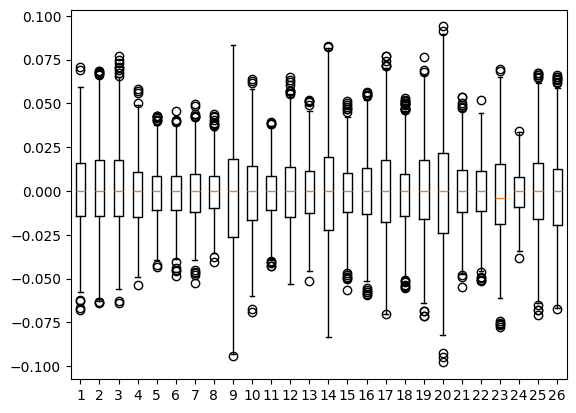

In [ ]:
plt.boxplot(trans1)

In [ ]:
print(pg.multivariate_normality(ret))
print(pg.multivariate_normality(trans1))

HZResults(hz=np.float64(31.901736176692374), pval=np.float64(0.0), normal=False)
HZResults(hz=np.float64(5.182727000089974), pval=np.float64(0.0), normal=False)
